In [1]:
import numpy as np
import pandas as pd

In [2]:
df= pd.read_csv("language.csv")

In [3]:
df.head(10)

,Text,language
0,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuit...,Swedish
2,ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...,Thai
3,விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...,Tamil
4,de spons behoort tot het geslacht haliclona en...,Dutch
5,エノが行きがかりでバスに乗ってしまい、気分が悪くなった際に助けるが、今すぐバスを降りたいと運...,Japanese
6,tsutinalar i̇ngilizce tsuutina kanadada albert...,Turkish
7,müller mox figura centralis circulorum doctoru...,Latin
8,برقی بار electric charge تمام زیرجوہری ذرات کی...,Urdu
9,シャーリー・フィールドは、サン・ベルナルド・アベニュー沿い市民センターとrtマーティン高校に...,Japanese


In [4]:
print("Total rows:\n", len(df))

Total rows:
 22000


In [5]:
print("Total col:\n", len(df.columns))

Total col:
 2


In [6]:
df.dtypes

Text        str
language    str
dtype: object

In [7]:
df.isnull().sum()

Text        0
language    0
dtype: int64

In [8]:
df["language"].value_counts()

language
Estonian      1000
Swedish       1000
Thai          1000
Tamil         1000
Dutch         1000
Japanese      1000
Turkish       1000
Latin         1000
Urdu          1000
Indonesian    1000
Portugese     1000
French        1000
Chinese       1000
Korean        1000
Hindi         1000
Spanish       1000
Pushto        1000
Persian       1000
Romanian      1000
Russian       1000
English       1000
Arabic        1000
Name: count, dtype: int64

In [9]:
df['Text'].duplicated().sum()

np.int64(141)

In [10]:
print(f"\nTotal missing: {df.isnull().sum().sum()}")
print(f"Duplicate texts: {df['Text'].duplicated().sum()}")


Total missing: 0
Duplicate texts: 141


In [11]:
df = df.drop_duplicates(subset='Text')
# Features and Target
X = df['Text']
y = df['language']

In [12]:
# Verify no duplicate texts carry conflicting language labels
conflicts = df.groupby('Text')['language'].nunique()
print("Texts with conflicting labels:", (conflicts > 1).sum())

Texts with conflicting labels: 0


In [13]:
import time
from sklearn.feature_extraction.text import TfidfVectorizer  #TF = Term Frequency,IDF = Inverse Document Frequency


In [14]:
tfidf = TfidfVectorizer(
    analyzer='char_wb',        # Character-level
    ngram_range=(1, 3),         # 1-3 char n-grams
    max_features=50000,         # Top 50,000 features
    lowercase=True,
    sublinear_tf=True           # Log scaling
)


In [15]:
from sklearn.model_selection import train_test_split

In [16]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X, y,
    test_size=0.33,
    random_state=42,
    stratify=y
)

In [17]:
start_time = time.time()
X_train = tfidf.fit_transform(X_train_text)    # fit on the training split only
X_test = tfidf.transform(X_test_text)          # transform only (no fitting) on the test split
vectorize_time = time.time() - start_time


In [18]:
print(f"Vectorization time: {vectorize_time:.2f} seconds")
print("Train:", X_train.shape, "Test:", X_test.shape)

Vectorization time: 71.50 seconds
Train: (14645, 50000) Test: (7214, 50000)


In [19]:
print(X_train.shape, X_test.shape, y_train.shape, y_test.shape)

(14645, 50000) (7214, 50000) (14645,) (7214,)


### Checking Training and Testing Data Shapes

We can check the shape of our training and testing datasets using either of the following methods.

**Method 1: Using f-strings (with labels)**

```python
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")
```

This method displays each shape with a clear label, making the output easier to understand.

**Method 2: Directly printing shapes**

```python
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)
```

This method displays the same information without additional labels.

**Note:** Both methods give the same results. The only difference is how the output is displayed.

- `X_train` and `X_test`: Show the number of training and testing samples (and features, if the data is two-dimensional).
- `y_train` and `y_test`: Show the number of corresponding language labels.

In [20]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score

### Model Dictionary
A dictionary is created to store three machine learning models.

- **Key:** Model name (string)
- **Value:** Model object

This allows us to train all three models using a single loop instead of writing separate code for each model.

### Storing Results

An empty dictionary `results` is created to store each model's accuracy and training time. It helps us save the outputs during the loop and compare the models later.

### Understanding the Training Loop

Let's understand how the loop works, step by step:

- `for`: Starts a loop that goes through each model one by one.
- `name`: Stores the name of the current model.
- `model`: Represents the current model object.
- `models.items()`: Provides both the model name and its corresponding model object from the dictionary.
- `model.fit(...)`: Trains the current model using the training data.
- `print(...)`: Displays the name of the model being trained.

**In simple words:** The loop selects one model at a time, trains it, and displays its name. This way, we can train all three models without repeating the same code.

### Measuring Model Training Time

- `start = time.time()`: Records the current time before training begins.
- `model.fit(X_train, y_train)`: Trains the model using the training data.
- `train_time = time.time() - start`: Calculates how many seconds the model took to complete training.

**In simple words:** We start a timer before training and calculate the total training time once the model finishes.

### Finding the Best Model

This code finds the model with the highest accuracy.

- `max()`: Finds the highest value.
- `results`: The dictionary containing all model results.
- `key=lambda x: ...`: Tells Python to compare models based on their accuracy.
- `results[x]['accuracy']`: Gets the accuracy of each model.

**What is lambda?**

`lambda` is a short function written in a single line.

In `lambda x: results[x]['accuracy']`:

- `x` represents the model name.
- `results[x]['accuracy']` returns that model's accuracy.

**Simple Example:** Imagine three students with different marks. Instead of comparing their names, we compare their marks and select the student with the highest score.

Similarly, this code compares model accuracies and selects the best-performing model.

### Method 1: Model Training Using a Loop
Efficiently train & compare multiple machine learning models.

In [21]:
models = {
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Linear SVC': LinearSVC(max_iter=2000)
}

results = {}

In [22]:
for name, model in models.items():
    start = time.time()

    model.fit(X_train, y_train)
    train_time = time.time() - start

    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    results[name] = {
        'accuracy': acc,
        'train_time': train_time
    }

    print(name)
    print("Accuracy:", round(acc * 100, 2), "%")
    print("Train time:", round(train_time, 2), "seconds")
    print()

Naive Bayes
Accuracy: 97.88 %
Train time: 0.67 seconds

Logistic Regression
Accuracy: 98.43 %
Train time: 46.68 seconds

Linear SVC
Accuracy: 98.82 %
Train time: 10.71 seconds



In [23]:
best_model = max(results, key=lambda name: results[name]['accuracy'])

print("Best Model:", best_model)
print("Best Accuracy:", round(results[best_model]['accuracy'] * 100, 2), "%")

fastest_model = min(results, key=lambda name: results[name]['train_time'])

print("Fastest Model:", fastest_model)
print("Fastest Train Time:", round(results[fastest_model]['train_time'], 2), "seconds")

Best Model: Linear SVC
Best Accuracy: 98.82 %
Fastest Model: Naive Bayes
Fastest Train Time: 0.67 seconds


### Method 2: Individual Model Training (For Learning)
Demonstrate the training & evaluation of each model separately.

In [24]:
start = time.time()

# Train
nb_model = MultinomialNB()
nb_model.fit(X_train, y_train)
# Stopwatch stop
nb_train_time = time.time() - start

nb_pred = nb_model.predict(X_test)
nb_acc = accuracy_score(y_test, nb_pred)

print("Accuracy:", nb_acc * 100, "%")
print("Train time:", nb_train_time, "seconds")
print("Predictions shape:", nb_pred.shape)

Accuracy: 97.87912392570003 %
Train time: 0.6099903583526611 seconds
Predictions shape: (7214,)


In [25]:
start= time.time()

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

lr_train_time= time.time()- start

lr_pred = lr.predict(X_test)
lr_acc = accuracy_score(y_test, lr_pred)

print(f"Train time:{lr_train_time:.2f} seconds")
print(f"Logistic Regression: {lr_acc*100:.2f}%")

Train time:40.06 seconds
Logistic Regression: 98.43%


In [26]:
start= time.time()

svc = LinearSVC(max_iter=2000)
svc.fit(X_train, y_train)

svc_train_time= time.time()- start

svc_pred = svc.predict(X_test)
svc_acc = accuracy_score(y_test, svc_pred)

print(f"Train time: {svc_train_time:.2f}seconds")
print(f"Linear SVC: {svc_acc*100:.2f}%")

Train time: 10.46seconds
Linear SVC: 98.82%


In [27]:
# to check best model

if nb_acc >= lr_acc and nb_acc >= svc_acc:
    print("Best Model: Naive Bayes")
    print("Accuracy:", nb_acc * 100, "%")

elif lr_acc >= nb_acc and lr_acc >= svc_acc:
    print("Best Model: Logistic Regression")
    print("Accuracy:", lr_acc * 100, "%")

else:
    print("Best Model: Linear SVC")
    print("Accuracy:", svc_acc * 100, "%")

Best Model: Linear SVC
Accuracy: 98.8217355142778 %


In [28]:
# to check fastest model

if nb_train_time <= lr_train_time and nb_train_time <= svc_train_time:
    print("Fastest Model: Naive Bayes")
    print("Train time:", nb_train_time, "seconds")

elif lr_train_time <= nb_train_time and lr_train_time <= svc_train_time:
    print("Fastest Model: Logistic Regression")
    print("Train time:", lr_train_time, "seconds")

else:
    print("Fastest Model: Linear SVC")
    print("Train time:", svc_train_time, "seconds")

Fastest Model: Naive Bayes
Train time: 0.6099903583526611 seconds


In [29]:
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [30]:
# Linear SVC  predictions
svc_pred = svc.predict(X_test)

print("Predictions shape:", svc_pred.shape)
print("First 10 predictions:", list(svc_pred[:10]))
print("First 10 actual:     ", list(y_test[:10]))

Predictions shape: (7214,)
First 10 predictions: ['Estonian', 'Spanish', 'Urdu', 'English', 'French', 'Japanese', 'Pushto', 'Chinese', 'Japanese', 'Portugese']
First 10 actual:      ['Estonian', 'Spanish', 'Urdu', 'English', 'French', 'Japanese', 'Pushto', 'Chinese', 'Japanese', 'Portugese']


In [31]:
report = classification_report(
    y_test,
    svc_pred,
    digits=3
)

print(report)

              precision    recall  f1-score   support

      Arabic      1.000     1.000     1.000       329
     Chinese      0.991     0.988     0.989       330
       Dutch      0.997     0.997     0.997       329
     English      0.853     1.000     0.921       330
    Estonian      0.994     0.985     0.989       330
      French      0.991     0.997     0.994       327
       Hindi      1.000     0.976     0.988       327
  Indonesian      1.000     0.988     0.994       322
    Japanese      1.000     0.997     0.998       330
      Korean      1.000     0.991     0.995       330
       Latin      0.962     0.968     0.965       314
     Persian      1.000     0.994     0.997       330
   Portugese      0.991     0.991     0.991       329
      Pushto      1.000     0.948     0.973       328
    Romanian      1.000     0.988     0.994       330
     Russian      0.994     0.994     0.994       329
     Spanish      0.997     0.985     0.991       329
     Swedish      1.000    

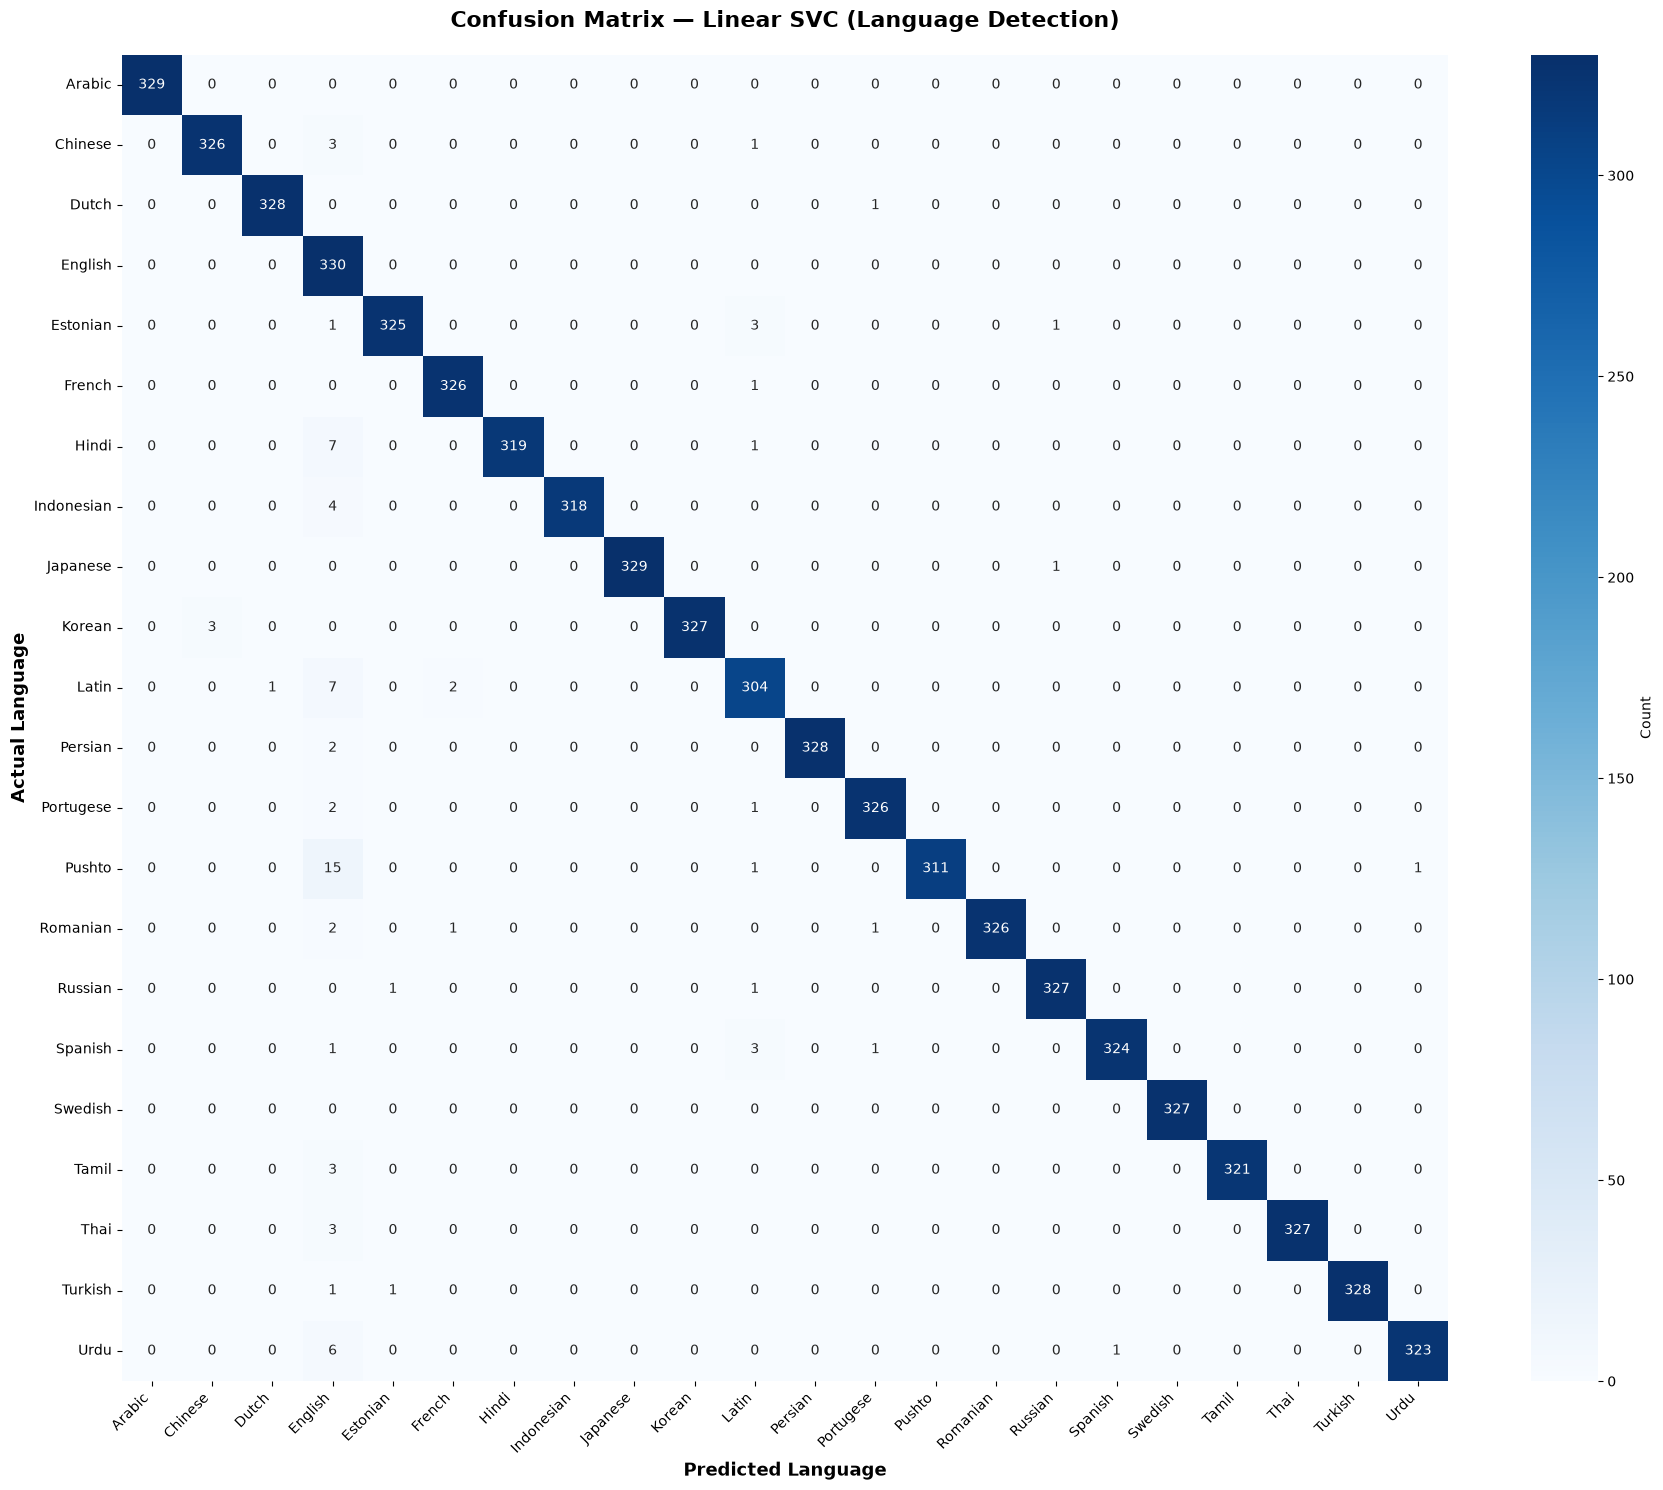

In [32]:


# Confusion matrix
cm = confusion_matrix(y_test, svc_pred)

class_names = sorted(y_test.unique())


# Heatmap
plt.figure(figsize=(18, 15))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=class_names,
    yticklabels=class_names,
    cbar_kws={'label': 'Count'}
)

plt.title('Confusion Matrix — Linear SVC (Language Detection)',
          fontsize=16, fontweight='bold', pad=20)
plt.xlabel('Predicted Language', fontsize=13, fontweight='bold')
plt.ylabel('Actual Language', fontsize=13, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

In [33]:
def predict_language(text):
    text_vector = tfidf.transform([text])
    prediction = svc.predict(text_vector)
    return prediction[0]

**Note:** German ("Guten Morgen!") and Italian ("Ciao, come stai?") are not among the 22 languages in the dataset, so these predictions are expected to be wrong: the model can only choose among its 22 classes.

In [34]:
# Testing multiple language examples

examples = [
    "Hello, how are you?",
    "Bonjour, comment allez-vous?",
    "Hola, buenos días.",
    "آپ کیسے ہیں؟",
    "مرحبا كيف حالك",
    "你好，你今天怎么样？",
    "Guten Morgen!",
    "Ciao, come stai?",
    "Привет, как дела?",
    "नमस्ते, आप कैसे हैं?"
]

for text in examples:
    prediction = predict_language(text)
    print(f"{text}  -->  {prediction}")

Hello, how are you?  -->  English
Bonjour, comment allez-vous?  -->  French
Hola, buenos días.  -->  Spanish
آپ کیسے ہیں؟  -->  Urdu
مرحبا كيف حالك  -->  Arabic
你好，你今天怎么样？  -->  Chinese
Guten Morgen!  -->  Dutch
Ciao, come stai?  -->  Portugese
Привет, как дела?  -->  Russian
नमस्ते, आप कैसे हैं?  -->  Hindi


### Error Analysis

To better understand the model's limitations, I examined misclassified test samples by comparing their actual and predicted language labels.

### How the error-analysis cell works
- `mask` marks the test samples whose predicted language differs from the actual label.
- `zip(...)` pairs each misclassified text with its actual and predicted language.
- The loop prints the first ten as `actual -> predicted | first 80 characters of the text`.

In [35]:
mask = (y_test.values != svc_pred)
for t, a, p in list(zip(X_test_text[mask], y_test[mask], svc_pred[mask]))[:10]:
    print(f"{a} -> {p} | {t[:80]}")

Dutch -> Portugese | armenia and the crusades tenth to twelfth centuries the chronicle of matthew of 
Indonesian -> English | wind-powered desalinization plant in perth australia is an example of how techno
Persian -> English | white andrew dickson  a history of the warfare of science with theology in chris
Portugese -> English | woelkerling wj  type collections of non-geniculate corallines housed at the labo
Latin -> Dutch | johann salomo semler versuch eines fruchtbaren auszugs der kirchengeschichte des
Japanese -> Russian | руська правда тексти на основі  списків та  редакцій склав та підготував до друк
Hindi -> English | in  the us established a central intelligence agency to coordinate its various f
Estonian -> Russian | p k pandajev "мракобесие для простаков или как один диакон искал сатанизм в будд
Tamil -> English | ramesh chandra majumdar  "hemu a forgotten hindu hero" the history and culture o
Indonesian -> English | inggris gundry robert h matthew a commentary on his literar

**Error Analysis Observation**
In the ten misclassified samples printed above, none of the texts matched its assigned label.

Manual inspection of selected misclassified samples revealed possible inconsistencies between some text samples and their assigned language labels. Several samples contained English text despite having non-English labels, while others appeared to use a different writing system from the assigned language.

These observations suggest that dataset quality may contribute to some classification errors. Further manual validation would be required to confirm potential labeling issues.

In [36]:
# Interactive test: type a sentence and get the predicted language
user_input = input("Enter text: ")
print("Prediction:", predict_language(user_input))



Enter text:  千里之行，始于足下。


Prediction: Chinese
